# SEED (modelo base)

El detector SEED original (semilla 42), sin método de incertidumbre. Es un solo modelo: toda su incertidumbre es aleatoria (la entropía de su probabilidad) y no tiene MI. Sirve como referencia para todos los demás métodos.


**Datos.** Evaluaciones 0, 1 y 2, cinco folds de test cada una (15 folds en total). Se leen los `test_predictions.npz` ya guardados: el notebook no entrena ni vuelve a inferir. Todo se calcula sobre los timesteps válidos.

**Cómo leer las tablas.** Cada tabla muestra *media ± desviación estándar* entre folds para cada evaluación (0, 1 y 2) y el promedio de las tres (los 15 folds juntos). Los gráficos tienen cuatro paneles con las mismas cuatro vistas.

**Definiciones que se repiten**

- *Cerca de eventos*: ±1 s alrededor de un huso real o predicho. Es donde ocurren los errores; el ~92% restante es fondo fácil que infla los AUROC.
- *Azar*: 0.5 para un AUROC; para un AUPRC, la proporción de positivos (tasa de error o proporción de FP/FN).
- *Aleatoria* = entropía esperada (ambigüedad de la señal); *epistémica* = MI (desacuerdo entre muestras del modelo); *total* = entropía predictiva = aleatoria + MI.
- *SEED H(p)*: la incertidumbre del SEED original sobre los mismos timesteps o eventos, como referencia.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

METHOD = 'SEED'
REFRESH = False  # True recalcula desde los NPZ (varios minutos)
results = report.method_results(METHOD, refresh=REFRESH)
metrics = results['metrics']

SEED: evaluación 0 lista
SEED: evaluación 1 lista
SEED: evaluación 2 lista


## 1. Detección y calibración

F1, precisión y recall por evento (IoU ≥ 0.2, métrica principal), AUROC/AUPRC de detección por timestep y calidad de la probabilidad (NLL, Brier y ECE de la clase positiva; menor es mejor).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 evento (%),82.38 ± 0.68,82.93 ± 0.88,82.83 ± 0.86,82.71 ± 0.79
precisión (%),83.5 ± 6.3,84.62 ± 2.9,82.41 ± 3.5,83.51 ± 4.3
recall (%),82.06 ± 6.5,81.46 ± 3.1,83.44 ± 2.8,82.32 ± 4.2
AUROC detección,0.9914 ± 0.00097,0.9916 ± 0.00071,0.9915 ± 0.00031,0.9915 ± 0.00067
AUPRC detección,0.8881 ± 0.0085,0.8899 ± 0.0045,0.8866 ± 0.0091,0.8882 ± 0.0072
NLL,0.05242 ± 0.0038,0.05036 ± 0.0022,0.05094 ± 0.0044,0.05124 ± 0.0035
Brier,0.01522 ± 0.0011,0.01478 ± 0.00059,0.01516 ± 0.0014,0.01505 ± 0.001
ECE clase positiva,0.007383 ± 0.0028,0.004797 ± 0.0019,0.005526 ± 0.0041,0.005902 ± 0.0031


F1 evento (%)  precisión (%)  recall (%)  AUROC detección  AUPRC detección     NLL   Brier  ECE clase positiva
evaluación fold                                                                                                                
0          0           82.3207        76.3559     89.2963           0.9915           0.8839  0.0537  0.0159              0.0114
           1           81.7017        83.6142     79.8748           0.9899           0.8769  0.0577  0.0164              0.0061
           2           83.0532        78.8611     87.7159           0.9918           0.8870  0.0514  0.0152              0.0077
           3           83.0839        86.2524     80.1400           0.9912           0.8981  0.0522  0.0153              0.0036
           4           81.7344        92.4020     73.2750           0.9926           0.8945  0.0472  0.0134              0.0081
1          0           83.1409        82.7206     83.5655           0.9921           0.8897  0.0474  0.0142              0.0051
           1           83.6570        85.1495     82.2160           0.9924           0.8968  0.0489  0.0145              0.0049
           2           81.7204        87.9630     76.3052           0.9916           0.8881  0.0507  0.0144              0.0067
           3           82.3317        80.6909     84.0406           0.9908           0.8845  0.0525  0.0156              0.0057
           4           83.7750        86.5514     81.1712           0.9910           0.8903  0.0524  0.0152              0.0016
2          0           82.4000        84.5128     80.3902           0.9911           0.8761  0.0487  0.0146              0.0029
           1           81.9659        76.7884     87.8920           0.9914           0.8956  0.0581  0.0175              0.0128
           2           82.3295        81.3976     83.2830           0.9918           0.8795  0.0477  0.0144              0.0042
           3           83.4552        85.0885     81.8834           0.9913           0.8859  0.0522  0.0153              0.0045
           4           84.0114        84.2505     83.7736           0.9918           0.8959  0.0480  0.0140              0.0033

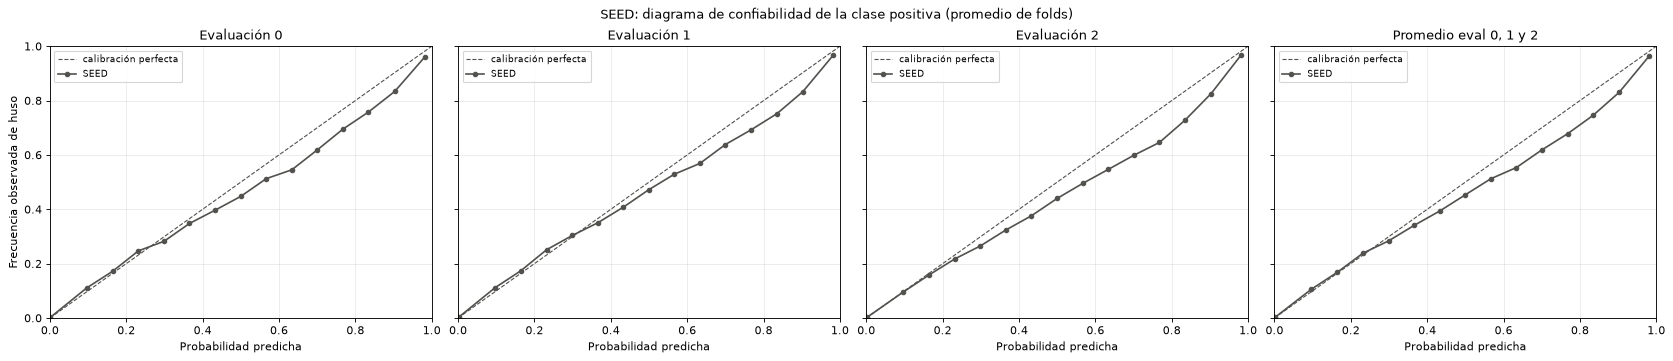

In [2]:
DETECTION = ['F1 evento (%)', 'precisión (%)', 'recall (%)', 'AUROC detección', 'AUPRC detección', 'NLL', 'Brier', 'ECE clase positiva']
display(report.by_evaluation(metrics, DETECTION))
display(metrics.set_index(['evaluación', 'fold'])[DETECTION].round(4))
show(report.plot_reliability(results, METHOD))

## 2. Curvas ROC

Curva promedio de los folds. *Detección*: huso vs fondo con la probabilidad. *Errores*: timesteps mal clasificados vs bien clasificados cerca de eventos, ordenados por cada medida de incertidumbre.

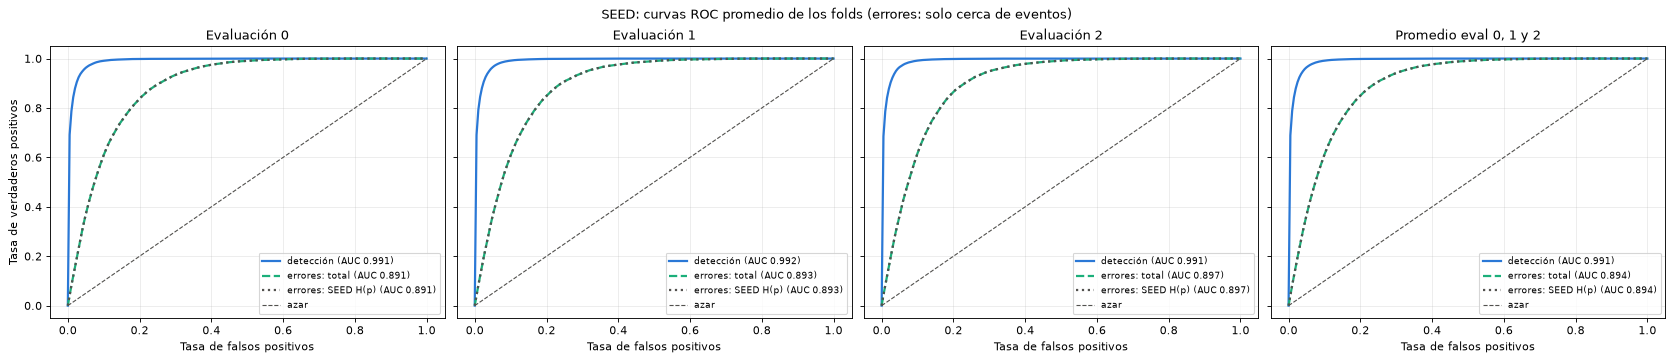

In [3]:
show(report.plot_roc(results, METHOD))

## 3. Descomposición de la incertidumbre

Entropía media en bits, en todo el registro y cerca de eventos, separada en aleatoria y epistémica (MI), con la incertidumbre de SEED como referencia.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
total (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
aleatoria (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
SEED H(p) (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
total (cerca de eventos),0.227 ± 0.01,0.227 ± 0.025,0.2346 ± 0.0082,0.2295 ± 0.016
aleatoria (cerca de eventos),0.227 ± 0.01,0.227 ± 0.025,0.2346 ± 0.0082,0.2295 ± 0.016
SEED H(p) (cerca de eventos),0.227 ± 0.01,0.227 ± 0.025,0.2346 ± 0.0082,0.2295 ± 0.016


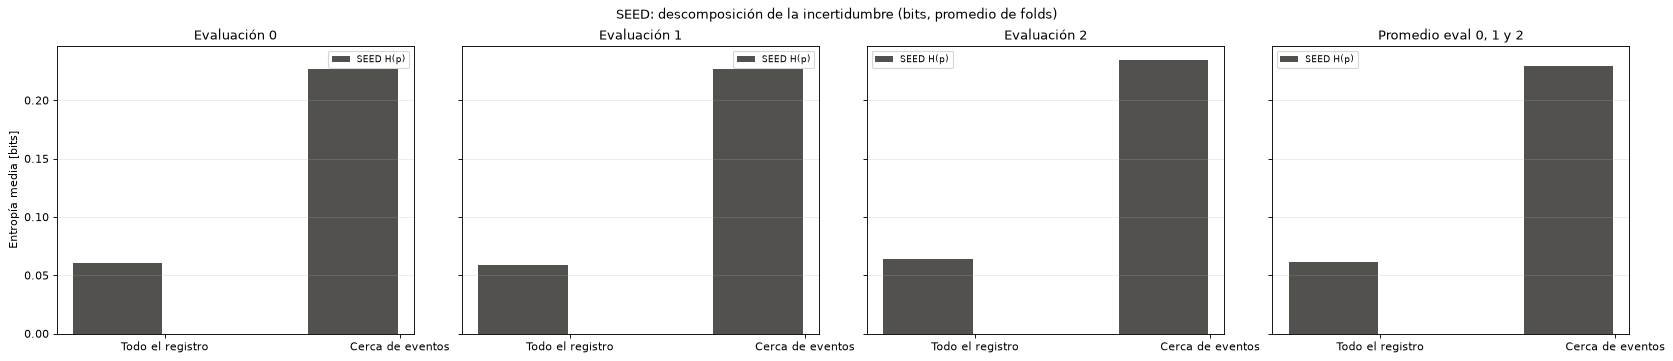

In [4]:
DECOMPOSITION = [c for c in metrics.columns if c.endswith('(registro)') or c.endswith('(cerca de eventos)')]
display(report.by_evaluation(metrics, DECOMPOSITION))
show(report.plot_decomposition(results, METHOD))

## 4. ¿La incertidumbre detecta los errores?

Errores por timestep cerca de eventos: AUROC y AUPRC de cada medida. El AUPRC se compara con la tasa de error (azar).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
AUROC errores: total,0.8912 ± 0.005,0.8929 ± 0.0069,0.8965 ± 0.0021,0.8935 ± 0.0052
AUPRC errores: total,0.4122 ± 0.0074,0.4093 ± 0.0092,0.4169 ± 0.0046,0.4128 ± 0.0075
AUROC errores: aleatoria,0.8912 ± 0.005,0.8929 ± 0.0069,0.8965 ± 0.0021,0.8935 ± 0.0052
AUPRC errores: aleatoria,0.4122 ± 0.0074,0.4093 ± 0.0092,0.4169 ± 0.0046,0.4128 ± 0.0075
AUROC errores: SEED H(p),0.8912 ± 0.005,0.8929 ± 0.0069,0.8965 ± 0.0021,0.8935 ± 0.0052
AUPRC errores: SEED H(p),0.4122 ± 0.0074,0.4093 ± 0.0092,0.4169 ± 0.0046,0.4128 ± 0.0075
azar errores,0.1048 ± 0.003,0.1029 ± 0.0047,0.104 ± 0.0041,0.1039 ± 0.0038


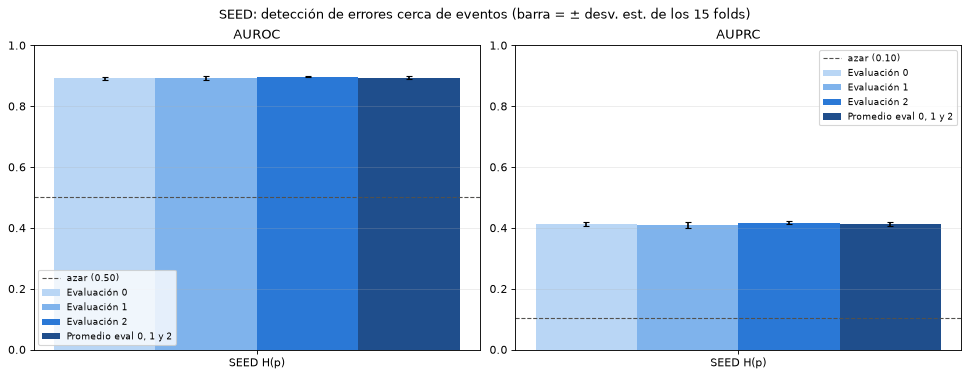

In [5]:
ERRORS = [c for c in metrics.columns if c.startswith('AUROC errores') or c.startswith('AUPRC errores')] + ['azar errores']
display(report.by_evaluation(metrics, ERRORS))
show(report.plot_error_detection(results, METHOD))

## 5. Dónde se concentra la incertidumbre

Entropía media por zona: bordes de los husos (±0.25 s del inicio o fin real), interior del huso y fondo.

Borde del huso
Interior del huso
Fondo


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,6.124 ± 0.34,6.124 ± 0.24,6.124 ± 0.36,6.124 ± 0.3
SEED H(p),0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021
aleatoria,0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,2.055 ± 0.25,2.055 ± 0.19,2.055 ± 0.2,2.055 ± 0.2
SEED H(p),0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062
aleatoria,0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,91.82 ± 0.53,91.82 ± 0.36,91.82 ± 0.55,91.82 ± 0.45
SEED H(p),0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077
aleatoria,0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077


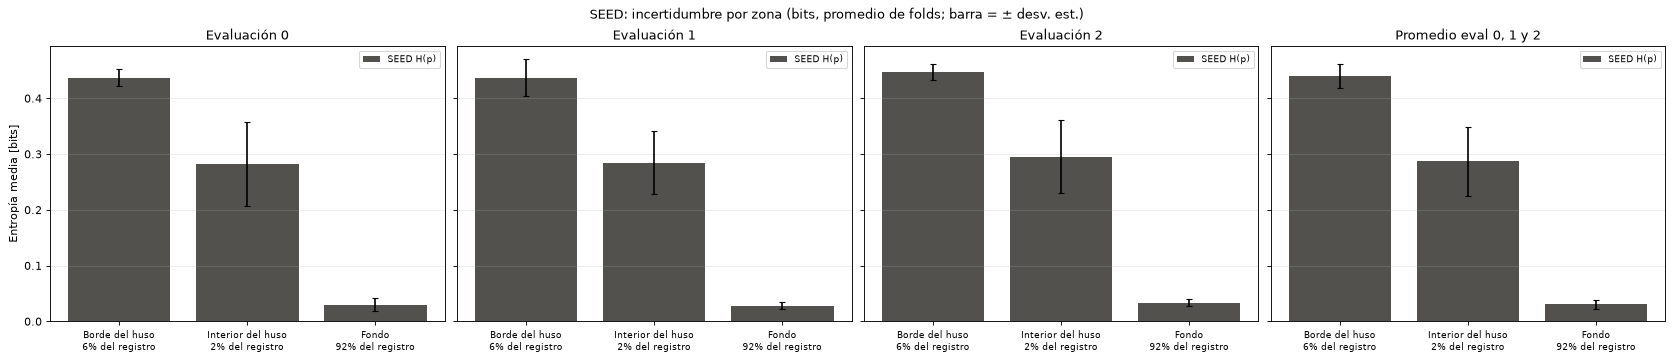

In [6]:
zones = results['zones']
for zone in ['Borde del huso', 'Interior del huso', 'Fondo']:
    print(zone)
    display(report.by_evaluation(zones[zones['zona'] == zone], [c for c in zones.columns if c not in ('evaluación', 'fold', 'zona')]))
show(report.plot_zones(results, METHOD))

## 6. Duración del evento vs incertidumbre

ρ es la correlación de Spearman entre la duración de cada evento predicho y su incertidumbre media (MI; para SEED, su entropía). ρ < 0: los eventos cortos son más inciertos.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
ρ duración-incertidumbre,-0.6609 ± 0.047,-0.6273 ± 0.073,-0.6166 ± 0.04,-0.6349 ± 0.055


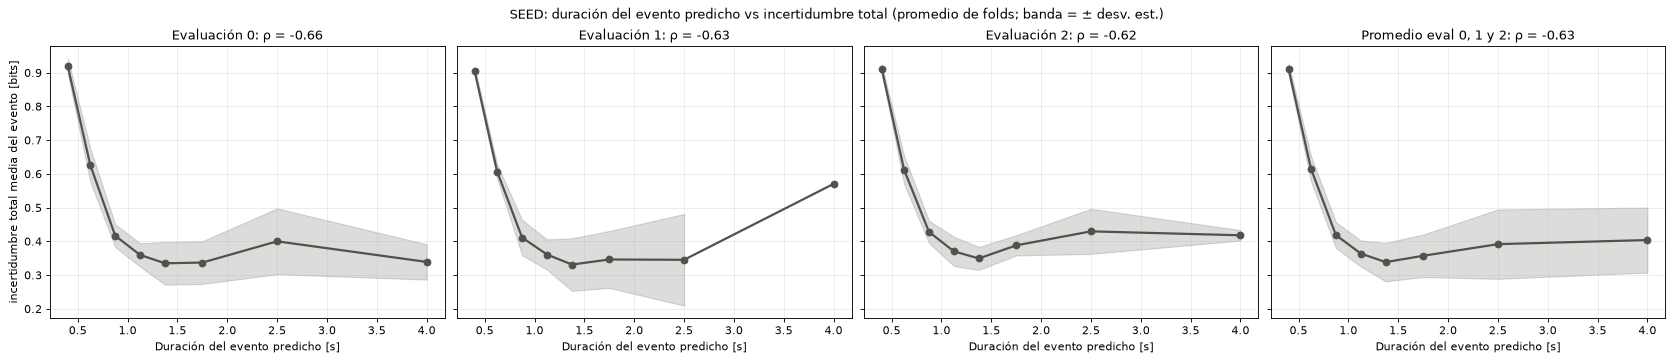

In [7]:
display(report.by_evaluation(metrics, ['ρ duración-incertidumbre']))
show(report.plot_duration(results, METHOD))

## 7. Aciertos, falsos positivos y falsos negativos

- **TP / FP (predicho)**: detecciones correctas y falsas, medidas en el tramo que el modelo predijo.
- **TP / FN (real)**: husos detectados y no detectados, medidos en el tramo real del huso (un FN no tiene tramo predicho). Los pares con IoU < 0.2 cuentan como FN, igual que en el F1.

Primero las medianas de cada medida, luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC con su azar), y al final los gráficos de cajón en percentil dentro del fold, con la línea de azar en 0.5. Comparar la *probabilidad media* entre FN y TP es casi circular (un FN es justamente un tramo con probabilidad baja).

Medianas por tipo de evento
FP vs TP (tramo predicho)
FN vs TP (tramo real)


eval 0                                           eval 1                                           eval 2                               promedio eval 0, 1 y 2                              
              probabilidad media incertidumbre total aleatoria probabilidad media incertidumbre total aleatoria probabilidad media incertidumbre total aleatoria     probabilidad media incertidumbre total aleatoria
grupo                                                                                                                                                                                                                
TP (predicho)             0.8799              0.4074    0.4074             0.8825              0.4077    0.4077             0.8799              0.4095    0.4095                 0.8807              0.4085    0.4085
FP (predicho)             0.6364              0.9248    0.9248             0.6445              0.9098    0.9098             0.6584              0.8949    0.8949                 0.6459              0.9112    0.9112
TP (real)                 0.8696              0.3711    0.3711             0.8690              0.3713    0.3713             0.8713              0.3767    0.3767                 0.8698              0.3737    0.3737
FN (real)                 0.1751              0.6030    0.6030             0.1787              0.6302    0.6302             0.1871              0.6233    0.6233                 0.1819              0.6187    0.6187

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.165 ± 0.063,0.1538 ± 0.029,0.1759 ± 0.035,0.1649 ± 0.043
AUROC probabilidad media,0.8541 ± 0.011,0.8465 ± 0.011,0.8455 ± 0.03,0.8487 ± 0.019
AUPRC probabilidad media,0.4723 ± 0.1,0.4629 ± 0.062,0.4897 ± 0.096,0.475 ± 0.082
AUROC incertidumbre total,0.856 ± 0.0099,0.8508 ± 0.011,0.8508 ± 0.03,0.8525 ± 0.018
AUPRC incertidumbre total,0.4557 ± 0.13,0.4522 ± 0.063,0.484 ± 0.11,0.464 ± 0.098
AUROC aleatoria,0.856 ± 0.0099,0.8508 ± 0.011,0.8508 ± 0.03,0.8525 ± 0.018
AUPRC aleatoria,0.4557 ± 0.13,0.4522 ± 0.063,0.484 ± 0.11,0.464 ± 0.098
AUROC SEED H(p),0.856 ± 0.0099,0.8508 ± 0.011,0.8508 ± 0.03,0.8525 ± 0.018
AUPRC SEED H(p),0.4557 ± 0.13,0.4522 ± 0.063,0.484 ± 0.11,0.464 ± 0.098


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1792 ± 0.065,0.1854 ± 0.031,0.1656 ± 0.028,0.1767 ± 0.042
AUROC probabilidad media,0.9542 ± 0.024,0.9645 ± 0.014,0.9561 ± 0.03,0.9583 ± 0.022
AUPRC probabilidad media,0.9339 ± 0.039,0.947 ± 0.017,0.9315 ± 0.048,0.9375 ± 0.035
AUROC incertidumbre total,0.5981 ± 0.084,0.6278 ± 0.042,0.6326 ± 0.044,0.6195 ± 0.058
AUPRC incertidumbre total,0.2232 ± 0.041,0.26 ± 0.032,0.2283 ± 0.016,0.2372 ± 0.034
AUROC aleatoria,0.5981 ± 0.084,0.6278 ± 0.042,0.6326 ± 0.044,0.6195 ± 0.058
AUPRC aleatoria,0.2232 ± 0.041,0.26 ± 0.032,0.2283 ± 0.016,0.2372 ± 0.034
AUROC SEED H(p),0.5981 ± 0.084,0.6278 ± 0.042,0.6326 ± 0.044,0.6195 ± 0.058
AUPRC SEED H(p),0.2232 ± 0.041,0.26 ± 0.032,0.2283 ± 0.016,0.2372 ± 0.034


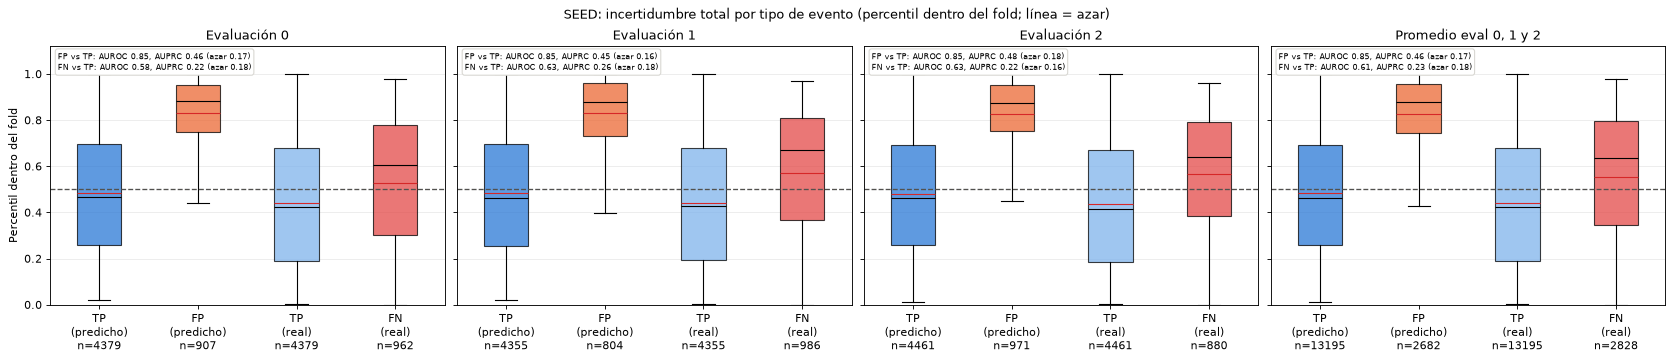

In [8]:
events = results['events']
print('Medianas por tipo de evento')
display(report.event_medians(events))
print('FP vs TP (tramo predicho)')
display(report.event_separation(events, 'TP (predicho)', 'FP (predicho)'))
print('FN vs TP (tramo real)')
display(report.event_separation(events, 'TP (real)', 'FN (real)'))
for figure in report.plot_event_boxes(results, METHOD):
    show(figure)

## 8. Derivar a revisión las detecciones más inciertas

Si se manda a revisión el x% de detecciones con más incertidumbre, ¿qué precisión tiene lo que se acepta automáticamente y qué parte de los falsos positivos se captura?

eval 0
eval 1
eval 2
promedio eval 0, 1 y 2


precisión aceptado (%)                     % de FP capturados                    
medida                  SEED H(p) incertidumbre total          SEED H(p) incertidumbre total
% derivado                                                                                  
0.0                          83.5                83.5                0.0                 0.0
5.0                          85.4                85.4               16.2                16.2
10.0                         87.2                87.2               31.0                31.0
20.0                         91.1                91.1               58.1                58.1
30.0                         94.2                94.2               77.1                77.1

precisión aceptado (%)                     % de FP capturados                    
medida                  SEED H(p) incertidumbre total          SEED H(p) incertidumbre total
% derivado                                                                                  
0.0                          84.6                84.6                0.0                 0.0
5.0                          86.5                86.5               16.4                16.4
10.0                         88.5                88.5               33.0                33.0
20.0                         91.8                91.8               57.5                57.5
30.0                         94.4                94.4               74.7                74.7

precisión aceptado (%)                     % de FP capturados                    
medida                  SEED H(p) incertidumbre total          SEED H(p) incertidumbre total
% derivado                                                                                  
0.0                          82.4                82.4                0.0                 0.0
5.0                          84.4                84.4               15.8                15.8
10.0                         86.4                86.4               30.3                30.3
20.0                         90.2                90.2               55.1                55.1
30.0                         93.8                93.8               75.1                75.1

precisión aceptado (%)                     % de FP capturados                    
medida                  SEED H(p) incertidumbre total          SEED H(p) incertidumbre total
% derivado                                                                                  
0.0                          83.5                83.5                0.0                 0.0
5.0                          85.4                85.4               16.1                16.1
10.0                         87.4                87.4               31.4                31.4
20.0                         91.0                91.0               56.9                56.9
30.0                         94.1                94.1               75.6                75.6

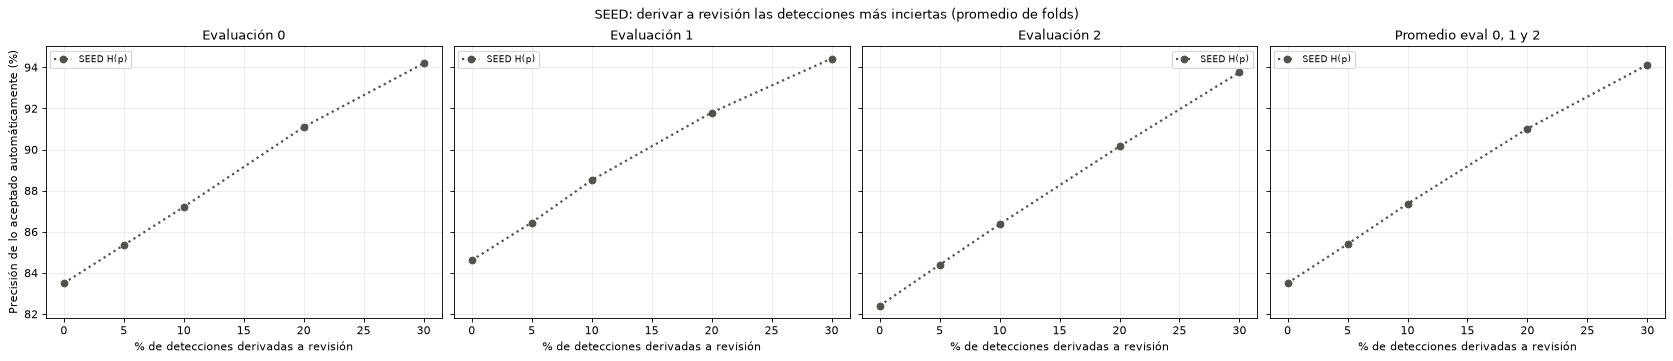

In [9]:
deferral = results['deferral'].dropna(subset=['% derivado'])
for label, part in [(f'eval {e}', deferral[deferral['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), deferral)]:
    print(label)
    display(part.groupby(['medida', '% derivado'])[['precisión aceptado (%)', '% de FP capturados']].mean().round(1).unstack('medida'))
show(report.plot_deferral(results, METHOD))

## 9. Descartar automáticamente las detecciones más inciertas

Sin revisión humana: se eliminan las detecciones con mayor incertidumbre (MI; para SEED, entropía). Los aciertos eliminados pasan a ser falsos negativos. Para que el F1 suba, más de ~58% de lo descartado debe ser FP (con F1 ≈ 83%, el equilibrio es 1 − F1/2).

FP descartados  TP descartados  % FP en lo descartado  cambio F1 (puntos)
medida              % descartado                                                                           
SEED H(p)           0.5                     2.47            2.73                  46.43               -0.06
                    1.0                     5.87            4.80                  53.95               -0.04
                    2.0                    11.67            9.47                  54.23               -0.08
                    5.0                    28.33           24.60                  52.45               -0.29
                    10.0                   55.33           50.53                  51.19               -0.72
                    20.0                  100.80          110.93                  46.52               -2.55
incertidumbre total 0.5                     2.47            2.73                  46.43               -0.06
                    1.0                     5.87            4.80                  53.95               -0.04
                    2.0                    11.67            9.47                  54.23               -0.08
                    5.0                    28.33           24.60                  52.45               -0.29
                    10.0                   55.33           50.53                  51.19               -0.72
                    20.0                  100.80          110.93                  46.52               -2.55

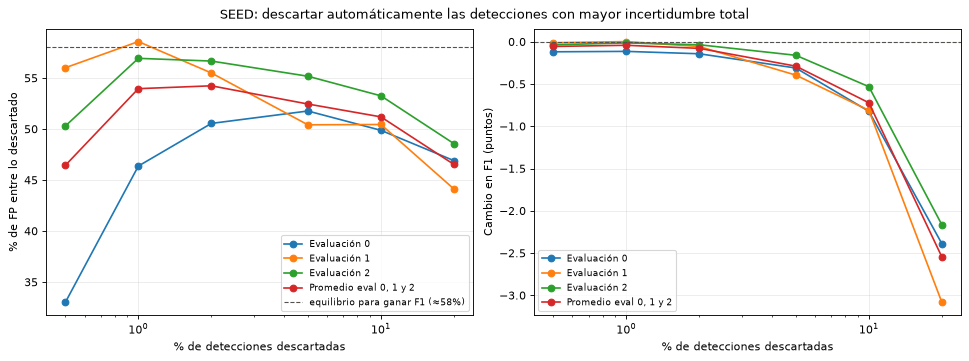

In [10]:
rejection = results['deferral'].dropna(subset=['% descartado'])
display(rejection.groupby(['medida', '% descartado'])[['FP descartados', 'TP descartados', '% FP en lo descartado', 'cambio F1 (puntos)']].mean().round(2))
show(report.plot_rejection(results, METHOD))

## 10. Información del método

Épocas de entrenamiento de SEED por fold.

In [11]:
info = results['info']
display(info.set_index(['evaluación', 'fold']).round(3))
display(report.by_evaluation(info))

épocas entrenadas
evaluación fold                   
0          0                     6
           1                     8
           2                     7
           3                     8
           4                     8
1          0                     7
           1                     8
           2                     7
           3                     8
           4                     8
2          0                     7
           1                     8
           2                     7
           3                     8
           4                     7

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
épocas entrenadas,7.4 ± 0.89,7.6 ± 0.55,7.4 ± 0.55,7.467 ± 0.64


## Hallazgos

Cifras como eval 0 / eval 1 / eval 2 / promedio de las tres (15 folds de test); un solo número es el promedio.

1. **Detección.** F1 por evento 82.4% / 82.9% / 82.8% / 82.7% (precisión 83.5%, recall 82.3% en promedio). ECE de clase positiva 0.007 / 0.005 / 0.006 / 0.006.
2. **La incertidumbre de SEED es aleatoria y está en los bordes de los husos:** 0.44 bits en los bordes, 0.29 en el interior y 0.03 en el fondo (~15 veces menos que en los bordes).
3. **Ya es un buen detector de errores:** AUROC 0.891 / 0.893 / 0.897 / 0.894 y AUPRC 0.41 (azar 0.10) cerca de eventos. Es la referencia que los demás métodos tienen que superar.
4. **Falsos positivos vs falsos negativos.** Su entropía separa los FP de los aciertos con AUROC 0.85, pero los FN solo con 0.62: cuando SEED pierde un huso lo hace con bastante seguridad (error silencioso).
5. **Los eventos cortos son más inciertos** (ρ = −0.66 / −0.63 / −0.62 / −0.63).
6. **Usar su incertidumbre:** derivar a revisión el 20% más incierto sube la precisión de lo aceptado de 83.5% a 91.0% y captura el 57% de los FP. Descartarlo automáticamente no sirve: entre lo descartado hay ~46–54% de FP y se necesitan >58% para que suba el F1, así que el F1 siempre baja.